<div>
    <span style ="font-size: 32px; font-weight: bold; color: #8EB944">
        Imports
    </span>
    
<hr style="color: #8EB944; height: 3px;background-color: #8EB944;border: none">
</div>

In [198]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
import numpy as np
from itertools import product


In [199]:
from prophet import Prophet
from prophet.diagnostics import cross_validation, performance_metrics
from prophet.plot import plot_cross_validation_metric

<div>
    <span style ="font-size: 32px; font-weight: bold; color: #8EB944">
        Define helper functions
    </span>
    
<hr style="color: #8EB944; height: 3px;background-color: #8EB944;border: none">
</div>

In [200]:
# Function to find gaps of at least 49 consecutive timestamps with 0 utilization
# more than 2 entire days (more than a weekend)
def find_gaps(df):
    # Create a mask for zero utilization
    zero_mask = df['utilization_absolute'] == 0
    
    # Initialize variables
    gaps = []
    start_idx = None
    
    # Iterate through the data
    for i in range(len(df)):
        if zero_mask.iloc[i]:
            if start_idx is None:
                start_idx = i
        else:
            if start_idx is not None:
                # Check if gap is at least 49 timestamps
                if i - start_idx >= 49:
                    gaps.append({
                        'start': df['timestamp'].iloc[start_idx],
                        'end': df['timestamp'].iloc[i-1],
                        'duration_hours': i - start_idx
                    })
                start_idx = None
    
    # Check for gap at the end of the dataset
    if start_idx is not None and len(df) - start_idx >= 49:
        gaps.append({
            'start': df['timestamp'].iloc[start_idx],
            'end': df['timestamp'].iloc[-1],
            'duration_hours': len(df) - start_idx
        })
    
    return gaps

In [228]:
def is_in_gap(timestamp, gaps):
    timestamp = pd.Timestamp(timestamp)
    return int(any(pd.Timestamp(gap['start']) <= timestamp <= pd.Timestamp(gap['end']) for gap in gaps))

In [202]:
def plot_forecast(data, start_date, end_date):
    # Ensure the index is a DatetimeIndex
    data = data.set_index('ds') if 'ds' in data.columns else data
    data.index = pd.to_datetime(data.index)  # Convert index to DatetimeIndex if not already
    
    # Slice the subset
    subset = data.loc[start_date:end_date]
    
    
    plt.figure(figsize=(12, 9))
    
    plt.subplot(411)
    plt.plot(subset.yhat)
    
    plt.tight_layout()
    plt.show()



def plot_subseries(data, start_date, end_date):
    # Ensure the index is a DatetimeIndex
    data = data.set_index('timestamp') if 'timestamp' in data.columns else data
    data.index = pd.to_datetime(data.index)  # Convert index to DatetimeIndex if not already
    
    # Slice the subset
    subset = data.loc[start_date:end_date]
    
    
    plt.figure(figsize=(12, 9))
    
    plt.subplot(411)
    plt.plot(subset.utilization_perc)
    
    plt.tight_layout()
    plt.show()

In [203]:
holidays_str = [
    '2018-01-01','2018-01-15', '2018-02-19','2018-03-31','2018-05-28','2018-07-04',
    '2018-09-03','2018-10-08','2018-11-12','2018-11-22','2018-11-23','2018-12-25',
    '2019-01-01','2019-01-21', '2019-02-18','2019-04-01','2019-05-27','2019-07-04',
    '2019-09-02','2019-11-11','2019-11-28','2019-11-29','2019-12-25',
    '2020-01-01','2020-01-20', '2020-02-17','2020-03-31','2020-05-25','2020-07-04',
    '2020-09-07','2020-11-11','2020-11-26','2020-11-27','2020-12-25',
    '2021-01-01','2021-01-18', '2021-02-15','2021-03-31','2021-05-31','2021-07-05',
    '2021-09-06','2021-11-11','2021-11-25','2021-11-26','2021-12-25',
    '2022-01-01','2022-01-17', '2022-02-21','2022-03-31','2022-05-30','2022-07-04',
    '2022-09-05','2022-11-11','2022-11-24','2022-11-25', '2022-12-26'

]



holidays = pd.DataFrame({
      'holiday': ['Holiday'] * len(holidays_str),  
    'ds': pd.to_datetime(holidays_str),
  'lower_window': 0,
  'upper_window': 0,
})

<div>
    <span style ="font-size: 32px; font-weight: bold; color: #8EB944">
        Hyperparameter Search
    </span>
    
<hr style="color: #8EB944; height: 3px;background-color: #8EB944;border: none">
</div>

In [98]:

# === Step 1: Define a grid of hyperparameters ===
param_grid = {
    'holidays_prior_scale': [1, 10, 50],
    'seasonality_prior_scale': [1, 10, 50],
    'changepoint_prior_scale': [0.05, 0.1, 0.5]
    
}
param_combinations = list(product(
    param_grid['holidays_prior_scale'],
    param_grid['seasonality_prior_scale'],
    param_grid['changepoint_prior_scale']
))

best_params = None
best_mae = float('inf')

# === Step 2: Perform Cross-Validation for each hyperparameter combination ===
for hps, sps, cps in param_combinations:
    model = Prophet(
        yearly_seasonality='auto',
        weekly_seasonality='auto',
        daily_seasonality='auto',
        holidays=holidays,
        holidays_prior_scale=hps,
        seasonality_prior_scale=sps,
        changepoint_prior_scale=cps,
        seasonality_mode='multiplicative',
    )
    
    model.fit(train_data)
    
    # Cross-validation
    df_cv = cross_validation(
        model,
        initial='365 days',
        period='60 days',
        horizon='14 days',
        parallel="processes"
    )
    
    # Compute metrics
    df_p = performance_metrics(df_cv, rolling_window=1)
    mae = df_p[df_p['horizon'] == '14 days']['mae'].mean()  # MAE for 14-day horizon
    
    # Update best parameters if current combination is better
    if mae < best_mae:
        best_mae = mae
        best_params = {'holidays_prior_scale': hps, 'seasonality_prior_scale': sps, 'changepoint_prior_scale': cps}

print(f"Best Parameters: {best_params}, Best MAE: {best_mae}")

16:51:43 - cmdstanpy - INFO - Chain [1] start processing
16:51:43 - cmdstanpy - INFO - Chain [1] start processing
16:51:43 - cmdstanpy - INFO - Chain [1] start processing
16:51:45 - cmdstanpy - INFO - Chain [1] done processing
16:51:45 - cmdstanpy - INFO - Chain [1] done processing
16:51:45 - cmdstanpy - INFO - Chain [1] done processing
16:51:53 - cmdstanpy - INFO - Chain [1] start processing
16:51:53 - cmdstanpy - INFO - Chain [1] start processing
16:51:53 - cmdstanpy - INFO - Chain [1] start processing
16:51:55 - cmdstanpy - INFO - Chain [1] done processing
16:51:56 - cmdstanpy - INFO - Chain [1] done processing
16:51:57 - cmdstanpy - INFO - Chain [1] done processing
16:52:03 - cmdstanpy - INFO - Chain [1] start processing
16:52:03 - cmdstanpy - INFO - Chain [1] start processing
16:52:03 - cmdstanpy - INFO - Chain [1] start processing
16:52:04 - cmdstanpy - INFO - Chain [1] done processing
16:52:05 - cmdstanpy - INFO - Chain [1] done processing
16:52:06 - cmdstanpy - INFO - Chain [1]

Best Parameters: {'holidays_prior_scale': 1, 'seasonality_prior_scale': 10, 'changepoint_prior_scale': 0.05}, Best MAE: 0.07862443936235378


<div>
    <span style ="font-size: 32px; font-weight: bold; color: #8EB944">
        Fit and Forecast
    </span>
    
<hr style="color: #8EB944; height: 3px;background-color: #8EB944;border: none">
</div>

In [350]:
# === Step 1: Prepare data ===
data = pd.read_csv('unfilled_utilizations.csv')
data = data[data.site_01==1]
data['post_covid'] = (data['timestamp'] >= '2020-03-17').astype(int)
data['in_gap'] = data['in_gap'].astype(int)

post_covid = data[data['timestamp'] >= '2020-03-17'].copy()
data_gaps = find_gaps(post_covid)
post_covid.rename(columns={'timestamp': 'ds', 'utilization_perc': 'y'}, inplace=True)



In [351]:
# === Step 2: Create a Train-Test split ===
train_data = post_covid[post_covid['ds'] < '2021-08-30']
test_data = post_covid[post_covid['ds'] >= '2021-08-30']

In [352]:
timestamps = []
for gap in data_gaps:
    timestamps.append(gap['start'])
    timestamps.append(gap['end'])

changepoint_dates = pd.to_datetime(timestamps)  
'''''' adding these individual changepoints increases the test error'''''


#seasonality_mode='multiplicative'
#    changepoints=changepoint_dates,
#    changepoint_prior_scale=0.1
# holidays_prior_scale=5

# === Step 3: Initialize  the Prophet Model ====

model = Prophet(
    yearly_seasonality='auto',
    weekly_seasonality=False,
    daily_seasonality=False,
    holidays=holidays,
    #scaling='absmax',
    seasonality_mode="multiplicative",
    holidays_prior_scale=1,
    changepoint_prior_scale=0.05,
    seasonality_prior_scale=50 
   
)

model.add_seasonality(name='daily', period=1, fourier_order=15)
model.add_seasonality(name='weekly', period=7, fourier_order=10)

model.add_regressor('in_gap', mode='multiplicative', prior_scale=0.5)
#model.add_regressor('post_covid', mode='additive', prior_scale=0.05)

In [353]:
# === Step 4: Fit the model ===
model.fit(train_data)



In [354]:
# ==== Step 5: Predict on Test data ===
# Ensure 'ds' column in test_data is in datetime format
test_data = test_data.copy()  # Create a copy to avoid modifying a view
train_data = train_data.copy()  # Create a copy for the same reason

test_data['ds'] = pd.to_datetime(test_data['ds'])
train_data['ds'] = pd.to_datetime(train_data['ds'])



forecast_test = model.predict(test_data[['ds', 'in_gap']])
test_data = test_data.merge(forecast_test[['ds', 'yhat']], on='ds', how='left')

# === Step 6: Evaluate errors on train Data ====


train_forecast = model.predict(train_data[['ds', 'in_gap']])
train_data = train_data.merge(train_forecast[['ds', 'yhat']], on='ds', how='left')

# Compute Metrics


metrics = {
    'Dataset': ['Training', 'Test'],
    'MAE': [
        mean_absolute_error(train_data['y'], train_data['yhat']),
        mean_absolute_error(test_data['y'], test_data['yhat'])
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(train_data['y'], train_data['yhat'])),
        np.sqrt(mean_squared_error(test_data['y'], test_data['yhat']))
    ]
}

metrics_df = pd.DataFrame(metrics)
print(metrics_df)

    Dataset       MAE      RMSE
0  Training  0.030601  0.054179
1      Test  0.068180  0.098249


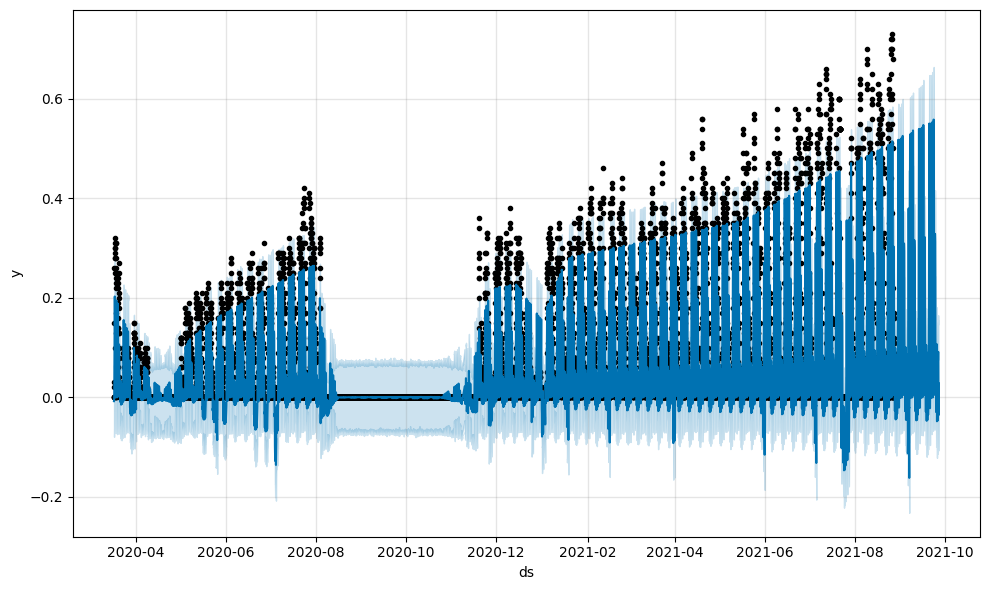

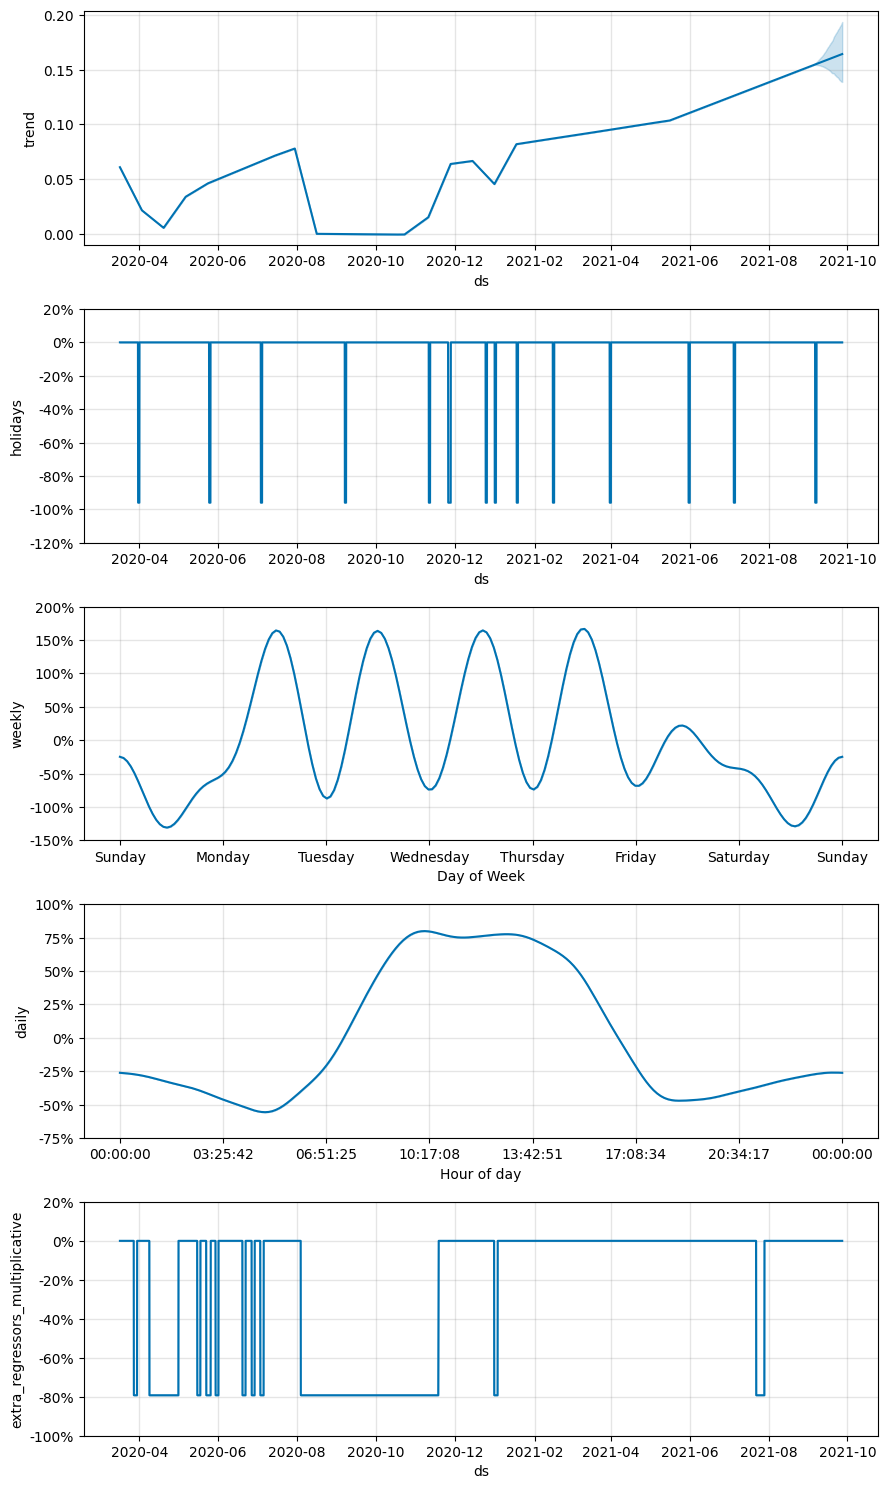

Forecasted utilisation for 22.09.2021 12 AM: 0.5514233816630688


In [355]:

# === Step 7: Forecast future dates ===
future = model.make_future_dataframe(periods=28 * 24, freq='H')  # Forecast 28 days of hourly data
holiday_dates = [
    '2022-01-01', '2022-01-17', '2022-02-21', '2022-03-31', '2022-05-30',
    '2022-07-04', '2022-09-05', '2022-11-11', '2022-11-24', '2022-11-25', '2022-12-26',
]
future['holiday'] = future['ds'].dt.date.isin(holiday_dates).astype(int)
future['in_gap'] = future['ds'].apply(lambda x: is_in_gap(x, data_gaps))

forecast = model.predict(future)

# === Step 8: Visualize the results ===
model.plot(forecast)
plt.show()

model.plot_components(forecast)
plt.show()

# === Step 9: Specific prediction  ===
specific_forecast = forecast.loc[forecast['ds'] == '2021-09-22 12:00']
print("Forecasted utilisation for 22.09.2021 12 AM:", specific_forecast['yhat'].values[0])